<a href="https://colab.research.google.com/github/Nicoll73/proyecto-ciencia-datos-spotify/blob/main/Proyecto_Etapas_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
**!git clone https://github.com/miguelmalgon-sys/proyecto-ciencia-datos-spotify.git
%cd proyecto-ciencia-datos-spotify


Cloning into 'proyecto-ciencia-datos-spotify'...
remote: Enumerating objects: 38, done.
remote: Counting objects: 100% (38/38), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 38 (delta 14), reused 29 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (38/38), 4.49 MiB | 8.45 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/proyecto-ciencia-datos-spotify


In [ ]:
import pandas as pd
import numpy as np

# Cargar el dataset limpio
df = pd.read_csv('datos/spotify_songs_limpio.csv')
print("Filas y columnas:", df.shape)
display(df.head())

# Detectar columnas numéricas
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Columnas numéricas:", num_cols)

# 1 y 2. Tendencia central (media, mediana, moda) y dispersión (rango, varianza, desv. estándar)
resumen = pd.DataFrame({
    'Media': df[num_cols].mean(),
    'Mediana': df[num_cols].median(),
    'Moda': df[num_cols].mode().iloc[0],
    'Minimo': df[num_cols].min(),
    'Maximo': df[num_cols].max(),
    'Rango': df[num_cols].max() - df[num_cols].min(),
    'Varianza': df[num_cols].var(),
    'Desv_Estandar': df[num_cols].std()
}).round(3)

display(resumen)

# 3. Comparación por género (si existe la columna playlist_genre)
if 'playlist_genre' in df.columns:
    display(df.groupby('playlist_genre')[num_cols].agg(['mean', 'median']).round(3))

# 4. Detección de outliers con IQR
outliers_info = {}
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    cant = df[(df[col] < lim_inf) | (df[col] > lim_sup)].shape[0]
    outliers_info[col] = {
        'Lim_Inf': round(lim_inf, 3),
        'Lim_Sup': round(lim_sup, 3),
        'Outliers': cant,
        'Porcentaje_%': round((cant / len(df)) * 100, 2)
    }

display(pd.DataFrame(outliers_info).T)


Filas y columnas: (28352, 24)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,playlist_name,playlist_id,playlist_genre,playlist_subgenre,...,acousticness,instrumentalness,liveness,valence,tempo,fecha_lanzamiento,anio,key_nota,modo,duracion_min
0,2XU0oxnq2qxCpomAAuJY8K,Dance Monkey,Tones and I,100,0UywfDKYlyiu1b38DRrzYD,Dance Monkey (Stripped Back) / Dance Monkey,Global Top 50 | 2020 Hits,1KNl4AYfgZtOVm9KHkhPTF,latin,latin hip hop,...,0.6920,0.000104,0.1490,0.513,98.027,2019-10-17,2019,F#,menor,3.490633
1,696DnlkuDOXcMAnKlTgXXK,ROXANNE,Arizona Zervas,99,6HJDrXs0hpebaRFKA1sF90,ROXANNE,Charts 2020 🔥Top 2020🔥Hits 2020🔥Summer 2020🔥Po...,3xMQTDLOIGvj3lWH5e5x6F,r&b,hip pop,...,0.0522,0.000000,0.4600,0.457,116.735,2019-10-10,2019,F#,menor,2.727267
2,2b8fOow8UzyDFAE27YhOZM,Memories,Maroon 5,98,3nR9B40hYLKLcR0Eph3Goc,Memories,Charts 2020 🔥Top 2020🔥Hits 2020🔥Summer 2020🔥Po...,3xMQTDLOIGvj3lWH5e5x6F,r&b,hip pop,...,0.8370,0.000000,0.0822,0.575,91.019,2019-09-20,2019,B,mayor,3.158100
3,21jGcNKet2qwijlDFuPiPb,Circles,Post Malone,98,4g1ZRSobMefqF6nelkgibi,Hollywood's Bleeding,Charts 2020 🔥Top 2020🔥Hits 2020🔥Summer 2020🔥Po...,3xMQTDLOIGvj3lWH5e5x6F,r&b,hip pop,...,0.1920,0.002440,0.0863,0.553,120.042,2019-09-06,2019,C,mayor,3.588000
4,7k4t7uLgtOxPwTpFmtJNTY,Tusa,KAROL G,98,7mKevNHhVnZER3BLgI8O4F,Tusa,Trap 2020 🔥,37DFLy7lqF3qiR99Ss2ZGR,rap,trap,...,0.2950,0.000134,0.0574,0.574,101.085,2019-11-07,2019,D,mayor,3.349333


Columnas numéricas: ['track_popularity', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'anio', 'duracion_min']


,Media,Mediana,Moda,Minimo,Maximo,Rango,Varianza,Desv_Estandar
track_popularity,39.335,42.000,0.000,0.000,100.000,100.000,561.664,23.699
danceability,0.653,0.670,0.690,0.000,0.983,0.983,0.021,0.146
energy,0.698,0.722,0.833,0.000,1.000,1.000,0.034,0.184
loudness,-6.818,-6.261,-5.824,-46.448,1.275,47.723,9.220,3.036
speechiness,0.108,0.063,0.103,0.000,0.918,0.918,0.011,0.103
acousticness,0.177,0.080,0.102,0.000,0.994,0.994,0.050,0.223
instrumentalness,0.091,0.000,0.000,0.000,0.994,0.994,0.054,0.233
liveness,0.191,0.127,0.111,0.000,0.996,0.996,0.024,0.156
valence,0.510,0.512,0.961,0.000,0.991,0.991,0.055,0.234
tempo,120.962,121.994,127.992,35.477,239.440,203.963,726.055,26.945


track_popularity        danceability        energy         \
                           mean median         mean median   mean median   
playlist_genre                                                             
edm                      32.007   34.0        0.657  0.660  0.806  0.833   
latin                    42.616   47.0        0.712  0.727  0.710  0.731   
pop                      43.500   47.0        0.637  0.649  0.702  0.728   
r&b                      37.541   39.0        0.669  0.688  0.590  0.595   
rap                      41.198   45.0        0.715  0.733  0.649  0.665   
rock                     40.133   45.0        0.519  0.521  0.734  0.779   

               loudness        speechiness         ... liveness         \
                   mean median        mean median  ...     mean median   
playlist_genre                                     ...                   
edm              -5.485 -5.000       0.088  0.061  ...    0.213  0.138   
latin            -6.433 -5.892       0.101  0.066  ...    0.182  0.121   
pop              -6.427 -5.911       0.073  0.048  ...    0.177  0.123   
r&b              -7.978 -7.523       0.116  0.068  ...    0.176  0.120   
rap              -7.127 -6.565       0.199  0.178  ...    0.191  0.127   
rock             -7.548 -6.951       0.058  0.042  ...    0.205  0.137   

               valence           tempo               anio          \
                  mean median     mean   median      mean  median   
playlist_genre                                                      
edm              0.400  0.368  126.077  127.317  2016.578  2018.0   
latin            0.607  0.630  118.581  112.016  2014.208  2017.0   
pop              0.503  0.499  121.050  120.026  2014.281  2016.0   
r&b              0.536  0.546  114.137  108.279  2008.910  2014.0   
rap              0.503  0.516  120.560  119.993  2012.829  2017.0   
rock             0.533  0.527  125.077  124.031  1998.268  2002.0   

               duracion_min         
                       mean median  
playlist_genre                      
edm                   3.749  3.411  
latin                 3.624  3.523  
pop                   3.641  3.520  
r&b                   3.995  3.919  
rap                   3.549  3.494  
rock                  4.133  3.948  

[6 rows x 24 columns]

,Lim_Inf,Lim_Sup,Outliers,Porcentaje_%
track_popularity,-34.500,113.500,0.0,0.00
danceability,0.263,1.058,257.0,0.91
energy,0.183,1.239,222.0,0.78
loudness,-13.712,0.693,837.0,2.95
speechiness,-0.097,0.271,2723.0,9.60
acousticness,-0.354,0.629,1911.0,6.74
instrumentalness,-0.010,0.016,6085.0,21.46
liveness,-0.142,0.484,1622.0,5.72
valence,-0.220,1.244,0.0,0.00
tempo,48.931,185.040,493.0,1.74


## Etapa 2 · Estadística Descriptiva y Preprocesamiento (`spotify_songs_limpio.csv`)

### 1. Medidas de tendencia central (media, mediana, moda)
- **Popularidad (`track_popularity`):** La media es **39.335**, la mediana es **42.000** y la moda es **0.000**. Esto indica que existe un grupo importante de canciones con popularidad cero, mientras que el centro del conjunto se ubica alrededor de los 40–42 puntos.
- **Atributos de audio (`danceability`, `energy`, `tempo`):** `danceability` tiene media **0.653**, mediana **0.670** y moda **0.690**, lo que muestra una distribución bastante equilibrada y tirando a valores moderados-altos. `energy` presenta media **0.698**, mediana **0.722** y moda **0.833**, reflejando temas en general energéticos. `tempo` ronda los **120.962** de media y **121.994** de mediana (moda **127.992**).

- **Duración y año (`duracion_min`, `anio`):** La duración media es **3.776 min** (mediana **3.616 min**, moda **4.000 min**), estándar para canciones comerciales. En `anio`, la media es **2011.054**, la mediana **2016.000** y la moda **2019.000**, evidenciando predominio de temas recientes con arrastre de canciones más antiguas.

### 2. Medidas de dispersión (rango, varianza, desviación estándar)
- **Alta dispersión:** `track_popularity` tiene un rango de **100.000** (0 a 100) y desviación estándar de **23.899** (varianza **561.664**), mostrando gran diferencia entre canciones poco escuchadas y éxitos masivos. `tempo` también varía bastante (rango **203.963**, desv. estándar **26.945**).

- **Dispersión moderada:** `danceability` (desv. estándar **0.146**, varianza **0.021**) y `energy` (desv. estándar **0.184**, varianza **0.034**) son más estables entre canciones.

### 3. Comparación entre variables (por `playlist_genre`)
- En la vista agrupada por género, **`pop`** (media **43.500**, mediana **47.0**) y **`latin`** (media **42.616**, mediana **47.0**) muestran mayor popularidad promedio que **`edm`** (media **32.007**).

- En atributos de audio, **`edm`** destaca por su alta energía promedio (**0.806**), mientras que **`rap`** (**0.715**) y **`latin`** (**0.712**) presentan mayor bailabilidad promedio que géneros como **`r&b`** (**0.595**).

### 4. Outliers, relaciones e hipótesis
- **Valores atípicos (*outliers*):** Se observan extremos en `track_popularity` (valores en `0` frente a picos cercanos a `98–100`), `tempo` (mínimos cerca de `35.477` y máximos cerca de `239.440`), `duracion_min` (desde `0.067` hasta `8.630` minutos) y `anio` (desde `1957` hasta `2020`).
- **Hipótesis planteadas:**
  1. El género de la playlist (`pop` y `latin` frente a `edm`) se asocia con diferencias en la popularidad promedio de las canciones.
  2. Debido a la presencia de valores extremos en variables como `tempo`, `duracion_min` y `anio`, la mediana describe mejor el caso "típico" que la media.


Para curaduría de playlists, marketing musical o sistemas de recomendación, apoyarse solo en promedios puede distorsionarse por canciones con popularidad cero o duraciones/tempos atípicos. Segmentar por género y revisar medianas junto con la dispersión permite identificar mejor qué características acompañan a los temas más populares en cada categoría.

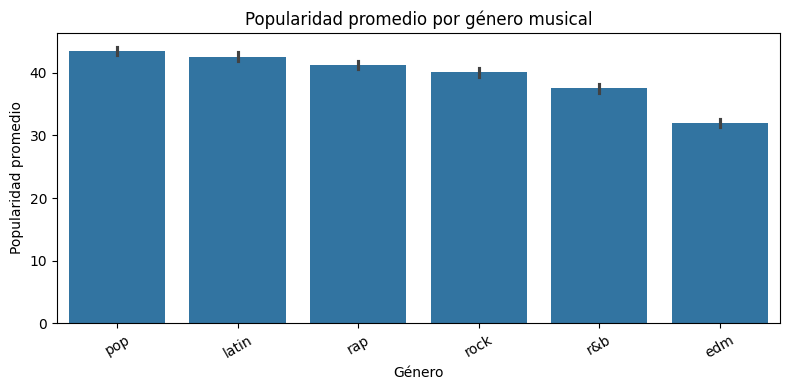

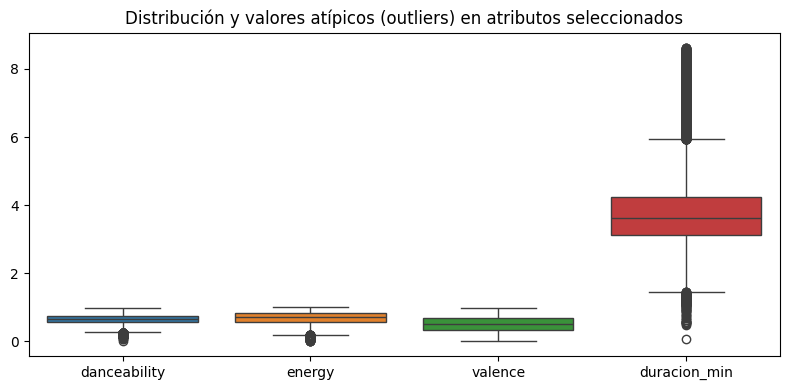

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico de popularidad promedio por género musical
if 'playlist_genre' in df.columns and 'track_popularity' in df.columns:
    plt.figure(figsize=(8, 4))
    orden = df.groupby('playlist_genre')['track_popularity'].mean().sort_values(ascending=False).index
    sns.barplot(data=df, x='playlist_genre', y='track_popularity', order=orden)
    plt.title('Popularidad promedio por género musical')
    plt.xlabel('Género')
    plt.ylabel('Popularidad promedio')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# 2. Boxplot de dispersión y outliers
cols_graf = [c for c in ['danceability', 'energy', 'valence', 'duracion_min'] if c in df.columns]
if cols_graf:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df[cols_graf])
    plt.title('Distribución y valores atípicos (outliers) en atributos seleccionados')
    plt.tight_layout()
    plt.show()